# RQ3 Analysis: Measure of Textual Lexical Diversity (MTLD)

Compares the lexical diversity (MTLD) of human-written vs. LLM-generated PR descriptions.

- Uses **TAALED** (Tool for the Automatic Analysis of Lexical Diversity) to compute MTLD.
- MTLD = mean length of sequential word strings that maintain a TTR ≥ 0.72 (McCarthy & Jarvis, 2010).
- Reports both **MTLD Original** (`mtldo` — forward-only) and **MTLD Bidirectional** (`mtld` — average of forward + backward).
- Uses `nltk.word_tokenize` for tokenization (consistent with TTR notebook).
- Compares across models and prompt context variations.

**Reference:** McCarthy, P. M., & Jarvis, S. (2010). MTLD, vocd-D, and HD-D: A validation study of sophisticated approaches to lexical diversity assessment. *Behavior Research Methods*, 42(2), 381–392.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.tokenize import word_tokenize
from scipy.stats import mannwhitneyu, kruskal
import scikit_posthocs as sp


In [2]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [3]:
csv_path = '../datasets/temperature_1/run_3/detection_results.csv'
df = pd.read_csv(csv_path)

In [4]:
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

In [5]:
# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

In [6]:
# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

In [7]:
# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

In [8]:
print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: <StringArray>
['meta-llama/llama-3.1-70b-instruct',             'gpt-5-mini-2025-08-07',
         'Qwen/Qwen2.5-72B-Instruct']
Length: 3, dtype: str
Human entries: 308, AI entries: 5528


## 2. Compute MTLD using TAALED

TAALED's `lexdiv` class computes multiple MTLD variants:
- **`mtldo`** — Original MTLD (forward-only pass; McCarthy & Jarvis, 2010)
- **`mtld`** / **`mtldav`** — Bidirectional MTLD (average of forward + backward passes)

We use `nltk.word_tokenize` for tokenization (consistent with the TTR notebook) and pass lowercased tokens to TAALED. Texts with fewer than 10 tokens are excluded as MTLD is unreliable for very short texts.

In [9]:
def _mtld_one_direction(tokens, thr=0.720):
    """Single-pass MTLD (McCarthy & Jarvis, 2010)."""
    if not tokens:
        return np.nan
    factor_count = 0.0
    seen = set()
    n = 0
    total = len(tokens)
    for tok in tokens:
        n += 1
        seen.add(tok)
        ttr = len(seen) / n
        if ttr <= thr:
            factor_count += 1.0
            seen = set()
            n = 0
    if n > 0:
        ttr = len(seen) / n
        factor_count += (1.0 - ttr) / (1.0 - thr)
    if factor_count == 0:
        return np.nan
    return total / factor_count


def compute_mtld(text: str) -> dict:
    """Compute MTLD Original (forward) and Bidirectional (average of forward + backward)."""
    if pd.isna(text) or str(text).strip() == '':
        return {'mtld_original': np.nan, 'mtld_bidir': np.nan}
    tokens = word_tokenize(str(text).lower())
    if len(tokens) < 10:
        return {'mtld_original': np.nan, 'mtld_bidir': np.nan}
    try:
        fwd = _mtld_one_direction(tokens)
        bwd = _mtld_one_direction(list(reversed(tokens)))
        bidir = (fwd + bwd) / 2 if not (np.isnan(fwd) or np.isnan(bwd)) else np.nan
        return {'mtld_original': fwd, 'mtld_bidir': bidir}
    except Exception:
        return {'mtld_original': np.nan, 'mtld_bidir': np.nan}


In [10]:
# Apply to both subsets
human_mtld = human_df['text'].apply(compute_mtld).apply(pd.Series)
human_df = pd.concat([human_df, human_mtld], axis=1)

ai_mtld = ai_df['text'].apply(compute_mtld).apply(pd.Series)
ai_df = pd.concat([ai_df, ai_mtld], axis=1)

In [11]:
# Combine for analysis
combined_df = pd.concat([human_df, ai_df], ignore_index=True)
combined_df['source'] = combined_df['entry_type'].map({'human': 'Human', 'ai': 'AI'})
combined_df = combined_df.dropna(subset=['mtld_original'])

In [12]:
print("MTLD metrics computed.")
print(f"Combined dataset size: {len(combined_df)}")
display(combined_df[['entry_type', 'model', 'text', 'mtld_original', 'mtld_bidir']].head(10))

MTLD metrics computed.
Combined dataset size: 5591


,entry_type,model,text,mtld_original,mtld_bidir
0,human,Human,Fixes #8873 \r\n\r\n\r\n<!-- \r\n- Go through ...,52.323232,47.474312
1,human,Human,"Implements #1516. Selected fields (`ISBN`, `UR...",10.054983,14.360825
2,human,Human,"Fixes #8108 \r\n\r\nTheoretically works, but n...",54.269663,54.820163
3,human,Human,Fixes #3905\r\n\r\n<!-- describe the changes y...,39.523852,37.657813
5,human,Human,Fixes #8654\r\nThis allows for the right click...,50.882421,54.399691
6,human,Human,# Changed database structure: table names are ...,32.090196,29.707625
7,human,Human,See #2789.\r\n> JabRef version 4.0.0-beta on W...,77.440000,77.440000
8,human,Human,Fixes #3584\r\n\r\n(No changelod needed as thi...,59.169811,46.428656
9,human,Human,…tting down\r\n\r\nFixes #2486. Unregistering ...,87.808000,87.808000
10,human,Human,Fix #1776 remove Cookie Handler implementation...,125.692000,125.692000


## 3. Descriptive Statistics: Human vs AI (Overall)

In [13]:
print(f"\n{'='*60}")
print("  MTLD (Original) — Descriptive Statistics")
print(f"{'='*60}")


  MTLD (Original) — Descriptive Statistics


In [14]:
stats = combined_df.groupby('source')['mtld_original'].describe()
stats['median'] = combined_df.groupby('source')['mtld_original'].median()
display(stats)

,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5296.0,67.880237,25.318202,10.111111,51.219948,65.500934,80.923199,304.92,65.500934
Human,295.0,56.498466,21.210093,10.054983,44.625568,52.514851,61.717648,189.28,52.514851


In [15]:
for src in ['Human', 'AI']:
    vals = combined_df[combined_df['source'] == src]['mtld_original']
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f"  {src}: Q1={q1:.4f}, Median={vals.median():.4f}, Q3={q3:.4f}, IQR={q3 - q1:.4f}")

print()
print(f"{'='*60}")
print("  MTLD (Bidirectional) — Descriptive Statistics")
print(f"{'='*60}")

for src in ['Human', 'AI']:
    vals = combined_df[combined_df['source'] == src]['mtld_bidir']
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f"  {src}: Q1={q1:.4f}, Median={vals.median():.4f}, Q3={q3:.4f}, IQR={q3 - q1:.4f}")

  Human: Q1=44.6256, Median=52.5149, Q3=61.7176, IQR=17.0921
  AI: Q1=51.2199, Median=65.5009, Q3=80.9232, IQR=29.7033

  MTLD (Bidirectional) — Descriptive Statistics
  Human: Q1=45.0218, Median=52.0877, Q3=62.4609, IQR=17.4391
  AI: Q1=51.4988, Median=65.3549, Q3=81.0000, IQR=29.5012


## 4. Descriptive Statistics: By Model

In [16]:
print(f"\n{'='*60}")
print("  MTLD (Original) — By Model")
print(f"{'='*60}")


  MTLD (Original) — By Model


In [17]:
stats_model = combined_df.groupby('model')['mtld_original'].describe()
stats_model['Median'] = combined_df.groupby('model')['mtld_original'].median()
stats_model['Q1'] = combined_df.groupby('model')['mtld_original'].quantile(0.25)
stats_model['Q3'] = combined_df.groupby('model')['mtld_original'].quantile(0.75)
stats_model['IQR'] = stats_model['Q3'] - stats_model['Q1']

In [18]:
display(stats_model[['count', 'mean', 'std', 'Median', 'Q1', 'Q3', 'IQR']].rename(
    columns={'count': 'Count', 'mean': 'Mean', 'std': 'Std'}
))

,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,295.0,56.498466,21.210093,52.514851,44.625568,61.717648,17.092080
Qwen/Qwen2.5-72B-Instruct,1842.0,66.025078,23.630029,63.636364,50.634684,79.053333,28.418649
gpt-5-mini-2025-08-07,1842.0,74.970970,19.512242,72.987500,61.616215,86.489561,24.873346
meta-llama/llama-3.1-70b-instruct,1612.0,61.897651,30.601392,55.315172,42.746503,71.680000,28.933497


In [19]:
print(f"\n{'='*60}")
print("  MTLD (Bidirectional) — By Model")
print(f"{'='*60}")

stats_model_bi = combined_df.groupby('model')['mtld_bidir'].describe()
stats_model_bi['Median'] = combined_df.groupby('model')['mtld_bidir'].median()
stats_model_bi['Q1'] = combined_df.groupby('model')['mtld_bidir'].quantile(0.25)
stats_model_bi['Q3'] = combined_df.groupby('model')['mtld_bidir'].quantile(0.75)
stats_model_bi['IQR'] = stats_model_bi['Q3'] - stats_model_bi['Q1']

display(stats_model_bi[['count', 'mean', 'std', 'Median', 'Q1', 'Q3', 'IQR']].rename(
    columns={'count': 'Count', 'mean': 'Mean', 'std': 'Std'}
))


  MTLD (Bidirectional) — By Model


,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,295.0,55.857252,20.523760,52.087690,45.021794,62.460930,17.439136
Qwen/Qwen2.5-72B-Instruct,1842.0,65.019294,23.246316,63.000000,49.738419,77.315000,27.576581
gpt-5-mini-2025-08-07,1842.0,76.253342,19.067449,74.443158,63.092378,87.349960,24.257582
meta-llama/llama-3.1-70b-instruct,1612.0,61.730175,30.408633,54.880000,42.875000,71.435755,28.560755


## 5. Statistical Testing & Effect Size

In [20]:
def cliffs_delta(lst1: list, lst2: list) -> float:
    """Compute Cliff's Delta effect size."""
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y: dom += 1
            elif x < y: dom -= 1
    return dom / (m * n)

In [21]:
def interpret_cliffs_delta(d: float) -> str:
    d = abs(d)
    if d < 0.147: return "Negligible"
    elif d < 0.33: return "Small"
    elif d < 0.474: return "Medium"
    else: return "Large"

In [22]:
model_results = []

In [23]:
human_mtld_orig = combined_df[combined_df['source'] == 'Human']['mtld_original'].values
human_mtld_bi = combined_df[combined_df['source'] == 'Human']['mtld_bidir'].values

In [24]:
for model in ai_df['model'].unique():
    model_data = ai_df[ai_df['model'] == model].dropna(subset=['mtld_original'])

    for metric, col, human_vals in [
        ('MTLD Original', 'mtld_original', human_mtld_orig),
        ('MTLD Bidirectional', 'mtld_bidir', human_mtld_bi),
    ]:
        ai_vals = model_data[col].values

        stat, p = mannwhitneyu(human_vals, ai_vals, alternative='two-sided')
        cd = cliffs_delta(human_vals.tolist(), ai_vals.tolist())

        model_results.append({
            'Model': model,
            'Metric': metric,
            'Human Mean': round(np.mean(human_vals), 4),
            'Model Mean': round(np.mean(ai_vals), 4),
            'Human Median': round(np.median(human_vals), 4),
            'Model Median': round(np.median(ai_vals), 4),
            'U-Statistic': stat,
            'p-value': p,
            'Significant': 'Yes' if p < 0.05 else 'No',
            "Cliff's Delta": round(cd, 4),
            'Effect Size': interpret_cliffs_delta(cd)
        })

In [25]:
models = ai_df['model'].unique()

In [26]:
print(models)
model_results_df = pd.DataFrame(model_results)
display(model_results_df)

<StringArray>
['meta-llama/llama-3.1-70b-instruct',             'gpt-5-mini-2025-08-07',
         'Qwen/Qwen2.5-72B-Instruct']
Length: 3, dtype: str


,Model,Metric,Human Mean,Model Mean,Human Median,Model Median,U-Statistic,p-value,Significant,Cliff's Delta,Effect Size
0,meta-llama/llama-3.1-70b-instruct,MTLD Original,56.4985,61.8977,52.5149,55.3152,219488.0,3.551556e-02,Yes,-0.0769,Negligible
1,meta-llama/llama-3.1-70b-instruct,MTLD Bidirectional,55.8573,61.7302,52.0877,54.8800,218540.0,2.700451e-02,Yes,-0.0809,Negligible
2,gpt-5-mini-2025-08-07,MTLD Original,56.4985,74.9710,52.5149,72.9875,112638.0,8.867838e-59,Yes,-0.5854,Large
3,gpt-5-mini-2025-08-07,MTLD Bidirectional,55.8573,76.2533,52.0877,74.4432,96416.0,5.510701e-71,Yes,-0.6451,Large
4,Qwen/Qwen2.5-72B-Instruct,MTLD Original,56.4985,66.0251,52.5149,63.6364,189457.5,6.382937e-17,Yes,-0.3027,Small
5,Qwen/Qwen2.5-72B-Instruct,MTLD Bidirectional,55.8573,65.0193,52.0877,63.0000,190106.0,1.113446e-16,Yes,-0.3003,Small


## 6. Visualizations

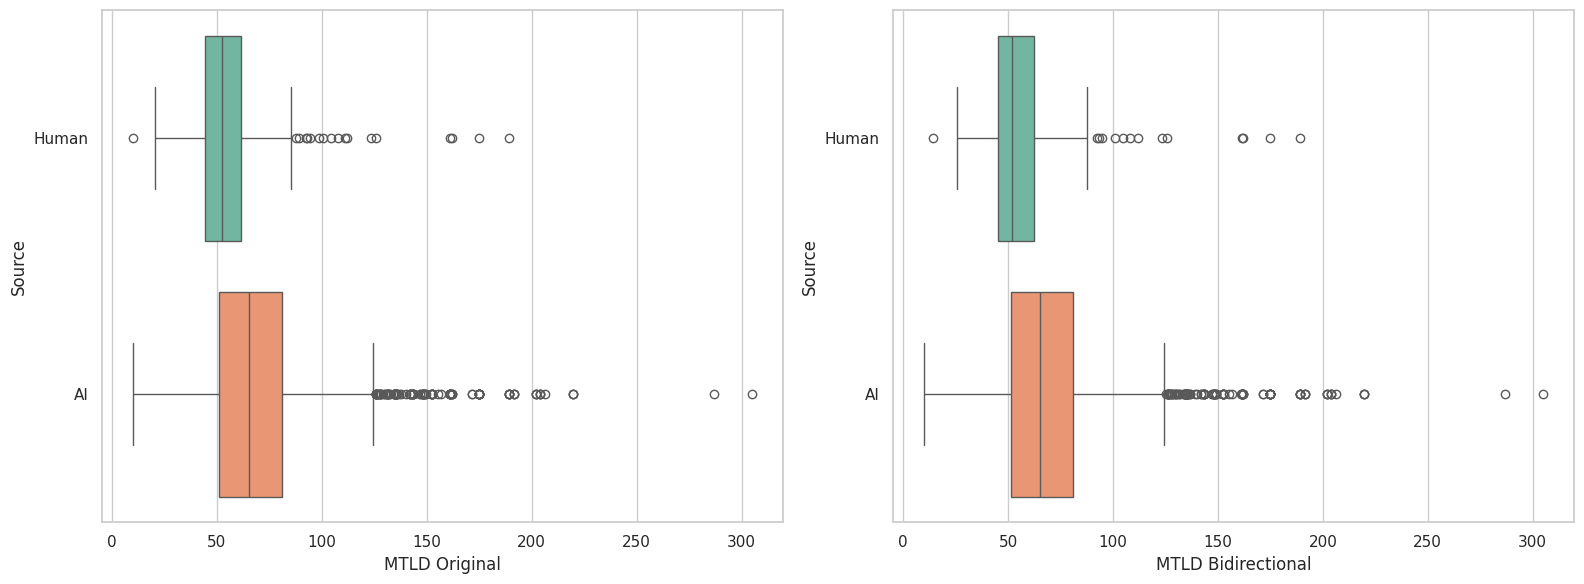

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=combined_df, x='mtld_original', y='source', hue='source',
            palette='Set2', legend=False, ax=axes[0])
axes[0].set_xlabel("MTLD Original", fontsize=12)
axes[0].set_ylabel("Source", fontsize=12)

sns.boxplot(data=combined_df, x='mtld_bidir', y='source', hue='source',
            palette='Set2', legend=False, ax=axes[1])
axes[1].set_xlabel("MTLD Bidirectional", fontsize=12)
axes[1].set_ylabel("Source", fontsize=12)

plt.tight_layout()
plt.show()

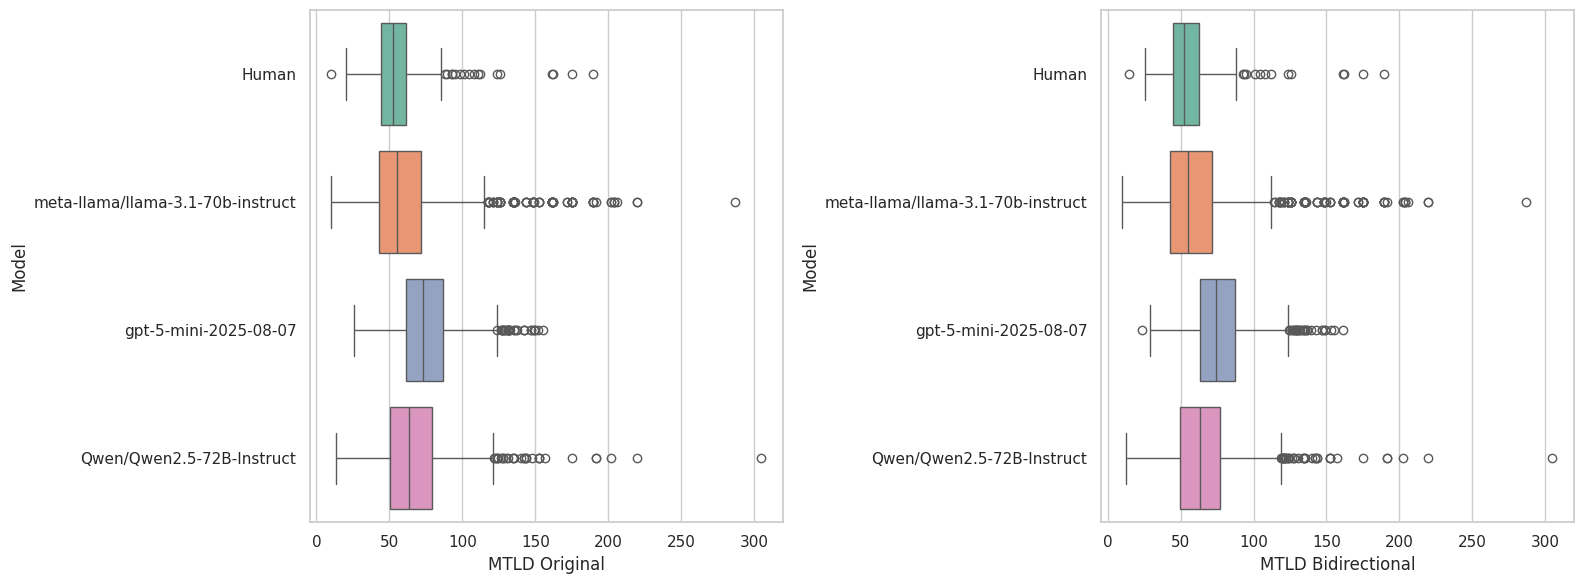

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

order = ['Human'] + list(models)

sns.boxplot(data=combined_df, x='mtld_original', y='model', order=order,
            hue='model', palette='Set2', legend=False, ax=axes[0])
axes[0].set_xlabel("MTLD Original", fontsize=12)
axes[0].set_ylabel("Model", fontsize=12)

sns.boxplot(data=combined_df, x='mtld_bidir', y='model', order=order,
            hue='model', palette='Set2', legend=False, ax=axes[1])
axes[1].set_xlabel("MTLD Bidirectional", fontsize=12)
axes[1].set_ylabel("Model", fontsize=12)

plt.tight_layout()
plt.show()

## 7. MTLD Boxplots by Context per LLM (with Human Baseline)

This mirrors the word-count, sentence-count, FKGL, and TTR setup:

- One panel per LLM model (stacked vertically).
- Each panel includes 6 AI context boxplots.
- A Human baseline boxplot is included in each panel for direct comparison.
- Rendered for both MTLD variants: `mtld_original` and `mtld_bidir`.

In [29]:
print(f"\n{'='*60}")
print("  MTLD (Original) — By Prompt Context Variation")
print(f"{'='*60}")


  MTLD (Original) — By Prompt Context Variation


In [30]:
# Filter to only AI data since 'human' entries don't have variation context
context_df = combined_df[combined_df['source'] == 'AI'].copy()
stats_ctx = context_df.groupby('Context_Name')['mtld_original'].describe()
stats_ctx['median'] = context_df.groupby('Context_Name')['mtld_original'].median()
display(stats_ctx)

,count,mean,std,min,25%,50%,75%,max,median
Context_Name,,,,,,,,,
File Contents,891.0,61.444062,21.537977,10.111111,46.048780,59.663912,75.109431,148.000000,59.663912
File Diff,889.0,62.173430,23.720124,15.000000,46.500000,59.765823,74.975385,206.173333,59.765823
Linked Issue,909.0,74.787457,23.876938,18.613636,58.127451,71.298969,87.808000,219.520000,71.298969
PR Title,871.0,81.276932,31.185449,22.308943,62.806154,75.321178,91.551515,304.920000,75.321178
Repo Path,820.0,62.769397,23.060322,12.791436,45.726484,62.564210,76.748000,155.407000,62.564210
Without File Contents,916.0,64.661555,20.537158,11.395010,49.835456,63.388167,78.415556,136.080000,63.388167


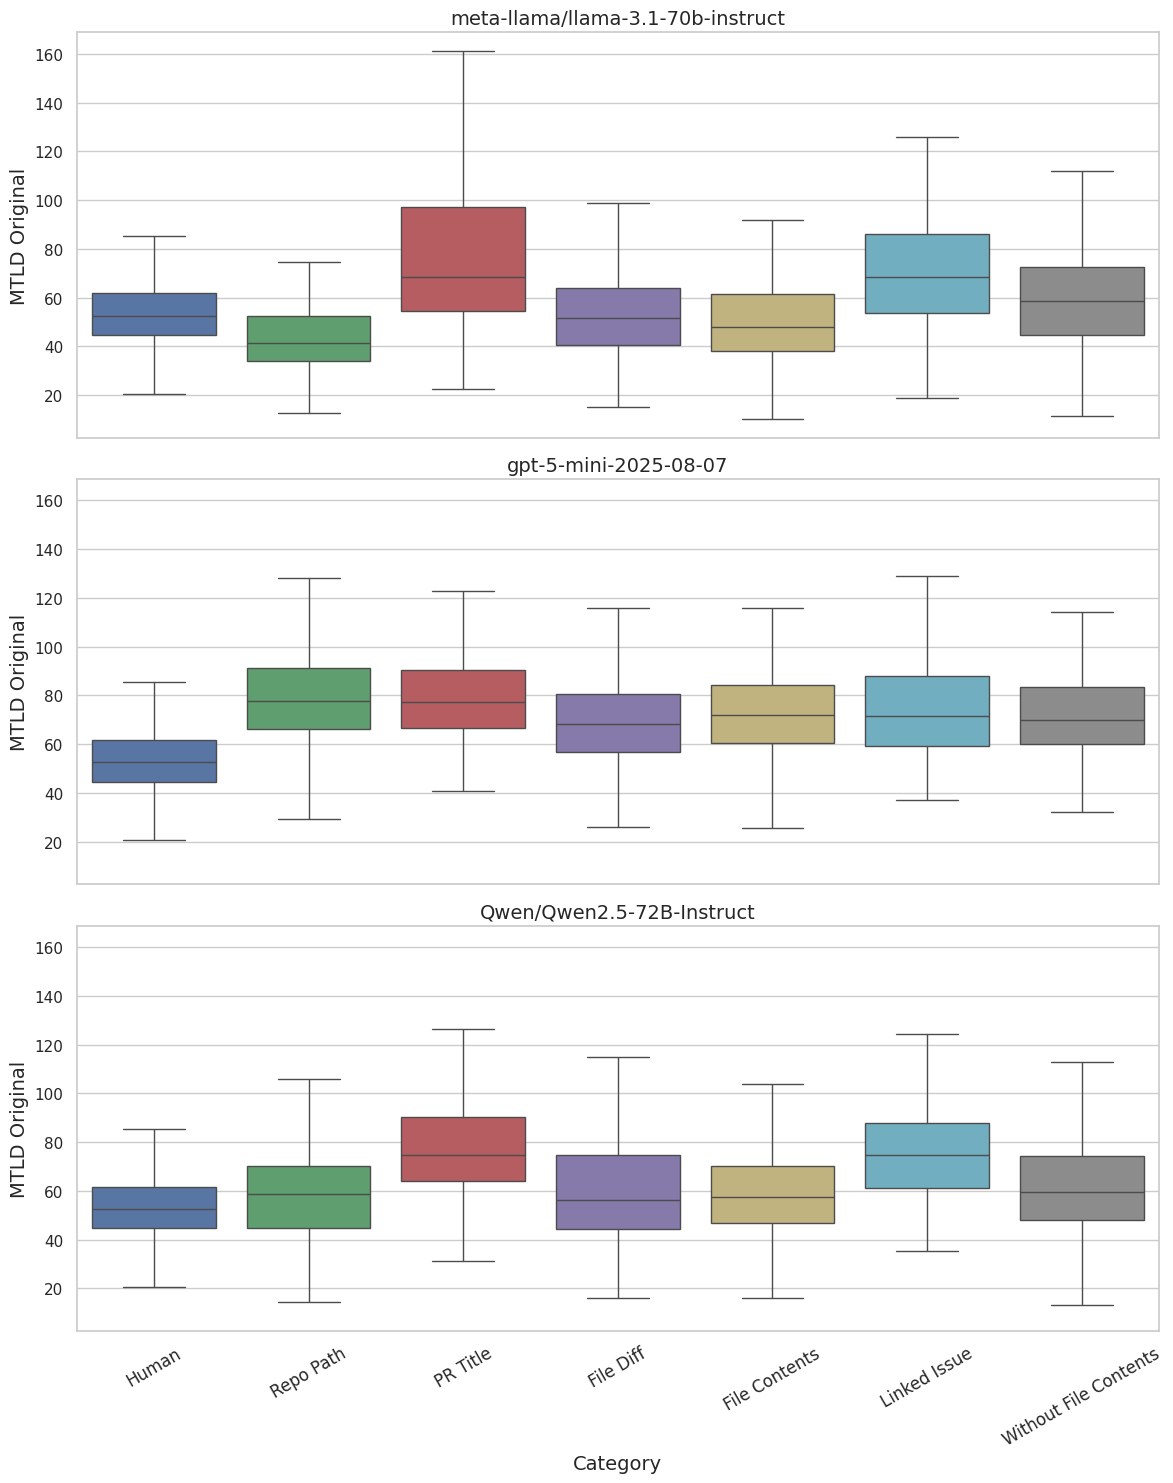

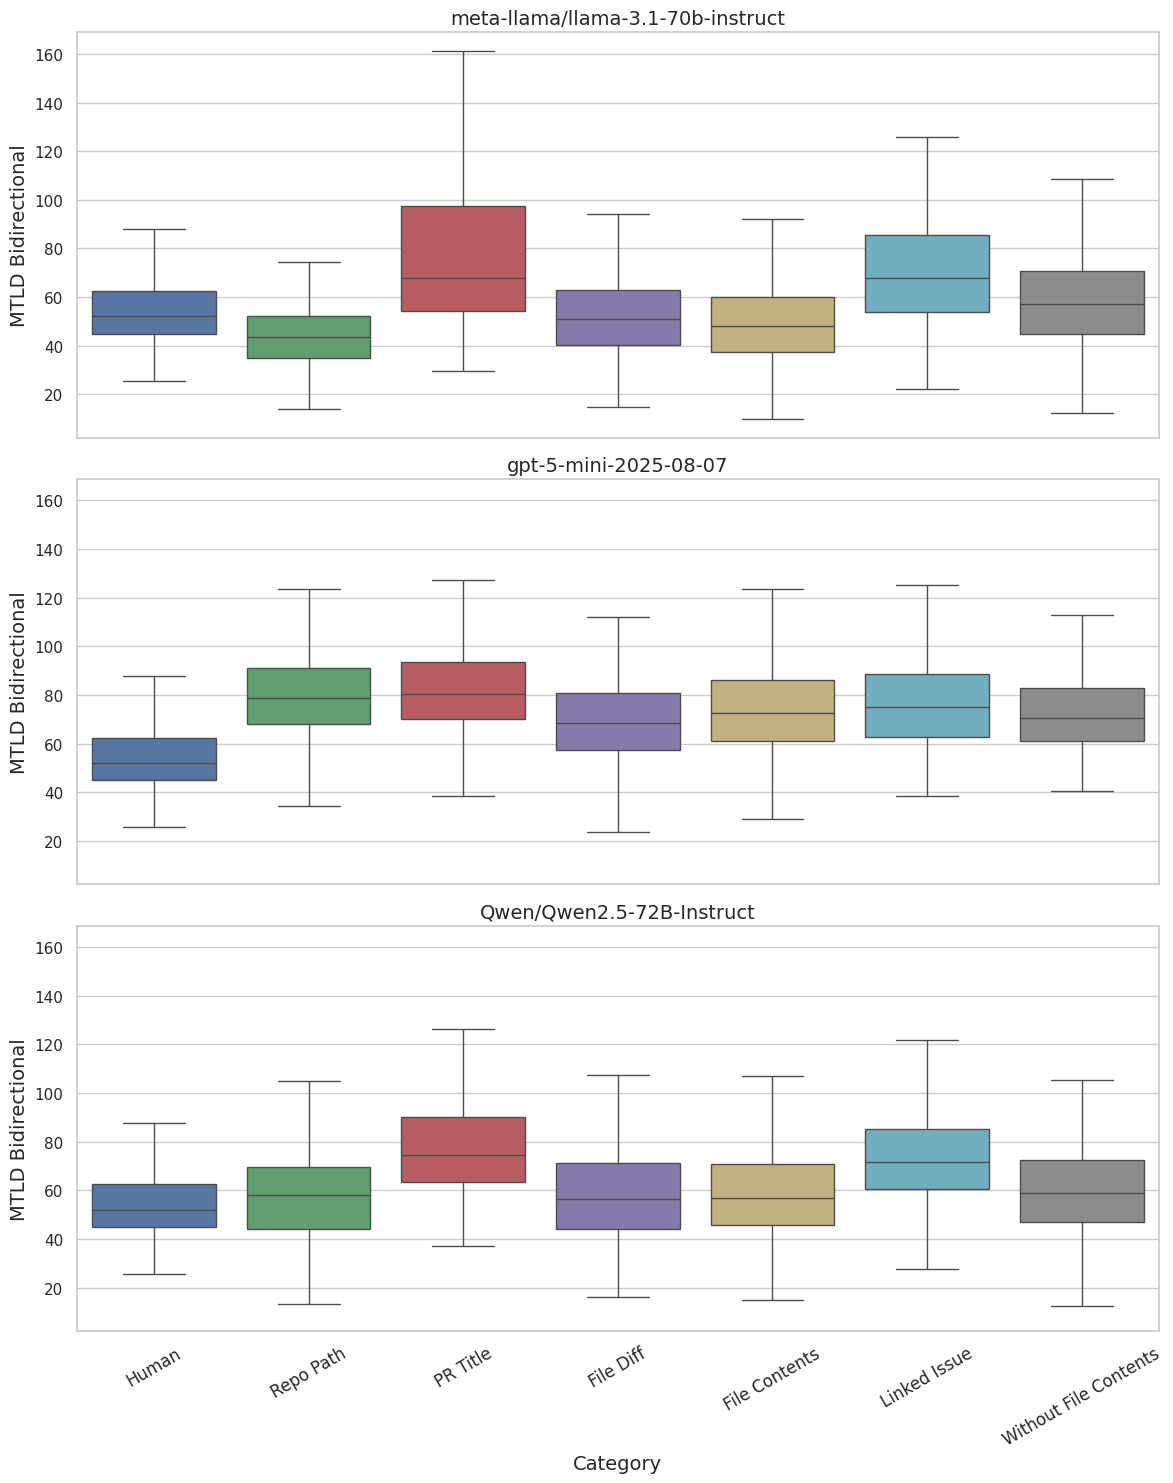

In [31]:
from pathlib import Path
OUT_DIR = Path('outputs/figures_pdf')
OUT_DIR.mkdir(parents=True, exist_ok=True)
context_order = [
    'Repo Path',
    'PR Title',
    'File Diff',
    'File Contents',
    'Linked Issue',
    'Without File Contents'
]

llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

def plot_mtld_by_context(metric_col: str, y_label: str, figure_title: str) -> None:
    fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)

    if len(llm_models) == 1:
        axes = [axes]

    for i, model in enumerate(llm_models):
        ax = axes[i]
        ax.set_title(model, fontsize=14)

        ai_slice = ai_df[ai_df['model'] == model][[metric_col, 'Context_Name']].dropna().copy()
        ai_slice['Category'] = ai_slice['Context_Name']

        human_slice = human_df[[metric_col]].dropna().copy()
        human_slice['Category'] = 'Human'

        panel_df = pd.concat([
            human_slice[[metric_col, 'Category']],
            ai_slice[[metric_col, 'Category']]
        ], ignore_index=True)

        sns.boxplot(
            data=panel_df,
            x='Category',
            y=metric_col,
            order=x_order,
            hue='Category',
            hue_order=x_order,
            ax=ax,
            palette=palette_map,
            dodge=False,
            legend=False,
            showfliers=False
        )

        ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=14)
        ax.set_ylabel(y_label, fontsize=14)
        ax.tick_params(axis='x', rotation=30, labelsize=12)

    plt.tight_layout()
    plt.savefig(str(OUT_DIR / (figure_title.replace(' ', '_').replace(':', '') + '.pdf')), bbox_inches='tight', dpi=150)
    plt.show()

plot_mtld_by_context('mtld_original', 'MTLD Original', 'MTLD Original Distribution: Human vs Contexts')
plot_mtld_by_context('mtld_bidir', 'MTLD Bidirectional', 'MTLD Bidirectional Distribution: Human vs Contexts')

## 8. Human vs. AI Context Variations (Cliff's δ Effect Sizes per Model)

For each model and each prompt context variation, we compare the paired Human descriptions against the AI-generated descriptions using Cliff's δ effect size measure for MTLD.

In [32]:
print(f"\n{'='*90}")
print("  Cliff's δ Effect Sizes: Human vs. AI Context Variations (MTLD)")
print(f"{'='*90}")


  Cliff's δ Effect Sizes: Human vs. AI Context Variations (MTLD)


In [33]:
model_names = ai_df['model'].unique()
variation_names = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']

In [34]:
rows_orig = []
rows_bidir = []

for model in model_names:
    row_orig = {'Model': model}
    row_bidir = {'Model': model}

    for variation in variation_names:
        # AI values for this model + variation (only paired PRs)
        ai_vals_orig = ai_df[
            (ai_df['model'] == model) & (ai_df['Context_Name'] == variation)
        ]['mtld_original'].dropna().values

        ai_vals_bidir = ai_df[
            (ai_df['model'] == model) & (ai_df['Context_Name'] == variation)
        ]['mtld_bidir'].dropna().values

        # Human values for the same paired PRs
        human_vals_orig = human_df['mtld_original'].dropna().values
        human_vals_bidir = human_df['mtld_bidir'].dropna().values

        # Compute Cliff's delta — MTLD Original
        delta_orig = cliffs_delta(list(human_vals_orig), list(ai_vals_orig))
        interp_orig = interpret_cliffs_delta(delta_orig)
        row_orig[variation] = f"{delta_orig:.3f} ({interp_orig})"

        # Compute Cliff's delta — MTLD Bidirectional
        delta_bidir = cliffs_delta(list(human_vals_bidir), list(ai_vals_bidir))
        interp_bidir = interpret_cliffs_delta(delta_bidir)
        row_bidir[variation] = f"{delta_bidir:.3f} ({interp_bidir})"

    rows_orig.append(row_orig)
    rows_bidir.append(row_bidir)

In [35]:
print("MTLD Original — Cliff's δ by Model × Context:")
result_orig_df = pd.DataFrame(rows_orig).set_index('Model')
display(result_orig_df)

print("\nMTLD Bidirectional — Cliff's δ by Model × Context:")
result_bidir_df = pd.DataFrame(rows_bidir).set_index('Model')
display(result_bidir_df)

MTLD Original — Cliff's δ by Model × Context:


,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
meta-llama/llama-3.1-70b-instruct,0.407 (Medium),-0.442 (Medium),0.058 (Negligible),0.173 (Small),-0.422 (Medium),-0.120 (Negligible)
gpt-5-mini-2025-08-07,-0.687 (Large),-0.692 (Large),-0.481 (Large),-0.548 (Large),-0.565 (Large),-0.539 (Large)
Qwen/Qwen2.5-72B-Instruct,-0.128 (Negligible),-0.648 (Large),-0.105 (Negligible),-0.141 (Negligible),-0.575 (Large),-0.216 (Small)



MTLD Bidirectional — Cliff's δ by Model × Context:


,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
meta-llama/llama-3.1-70b-instruct,0.390 (Medium),-0.452 (Medium),0.066 (Negligible),0.181 (Small),-0.430 (Medium),-0.129 (Negligible)
gpt-5-mini-2025-08-07,-0.747 (Large),-0.752 (Large),-0.519 (Large),-0.600 (Large),-0.646 (Large),-0.606 (Large)
Qwen/Qwen2.5-72B-Instruct,-0.105 (Negligible),-0.662 (Large),-0.113 (Negligible),-0.145 (Negligible),-0.580 (Large),-0.194 (Small)


## 9. Summary Table

In [36]:
summary_rows = []

In [37]:
for model in combined_df['model'].unique():
    subset = combined_df[combined_df['model'] == model]

    for metric, col in [('MTLD Original', 'mtld_original'), ('MTLD Bidirectional', 'mtld_bidir')]:
        vals = subset[col].dropna()
        summary_rows.append({
            'Model': model,
            'Metric': metric,
            'N': len(vals),
            'Mean': round(vals.mean(), 4),
            'Median': round(vals.median(), 4),
            'Std': round(vals.std(), 4),
            'Min': round(vals.min(), 4),
            'Max': round(vals.max(), 4),
            'Q1': round(vals.quantile(0.25), 4),
            'Q3': round(vals.quantile(0.75), 4)
        })

In [38]:
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,MTLD Original,295,56.4985,52.5149,21.2101,10.0550,189.2800,44.6256,61.7176
1,Human,MTLD Bidirectional,295,55.8573,52.0877,20.5238,14.3608,189.2800,45.0218,62.4609
2,meta-llama/llama-3.1-70b-instruct,MTLD Original,1612,61.8977,55.3152,30.6014,10.1111,286.7200,42.7465,71.6800
3,meta-llama/llama-3.1-70b-instruct,MTLD Bidirectional,1612,61.7302,54.8800,30.4086,9.8399,286.7200,42.8750,71.4358
4,gpt-5-mini-2025-08-07,MTLD Original,1842,74.9710,72.9875,19.5122,25.7443,155.4070,61.6162,86.4896
5,gpt-5-mini-2025-08-07,MTLD Bidirectional,1842,76.2533,74.4432,19.0674,23.5425,161.1468,63.0924,87.3500
6,Qwen/Qwen2.5-72B-Instruct,MTLD Original,1842,66.0251,63.6364,23.6300,13.1486,304.9200,50.6347,79.0533
7,Qwen/Qwen2.5-72B-Instruct,MTLD Bidirectional,1842,65.0193,63.0000,23.2463,12.5319,304.9200,49.7384,77.3150


In [39]:
import os
os.makedirs('outputs', exist_ok=True)

# Save summary to CSV
summary_df.to_csv('outputs/rq3_mtld_summary.csv', index=False)
print("\nSummary saved to outputs/rq3_mtld_summary.csv")


Summary saved to outputs/rq3_mtld_summary.csv
